[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/MQE_IntrusionDetection_Bhatnagar2026.ipynb)

# Meta-Quantum Ensemble (QSVM + QNN + Random-Forest meta-learner) for network intrusion detection: Bhatnagar et al. 2026 step by step

**Paper.** Ritvik Bhatnagar, Nouhaila Innan, Angel Arul Jothi J., Muhammad Shafique, *Meta-Quantum Ensemble Framework for Robust Network Intrusion Detection*, arXiv:2605.28879 [quant-ph], May 2026. https://arxiv.org/abs/2605.28879

**What this notebook does.** It rebuilds the paper's *System-Level Meta-Quantum Ensemble (MQE)* from scratch with PennyLane: two quantum learners (a quantum-kernel SVM and a variational quantum neural network with 7 strongly entangling layers on 13 qubits) whose outputs are fused by a classical Random-Forest meta-learner. It is evaluated on the paper's own two datasets, **CICIDS2017 (D1)** and **TON_IoT (D2)**, next to classical baselines (Random Forest, XGBoost, logistic regression) trained on exactly the same 13 inputs, and every number is put next to the value printed in the paper.

**How to run.** Google Colab, CPU runtime (no GPU needed), *Runtime -> Run all*. With `FAST_MODE = True` the notebook runs in roughly 10 minutes (small samples, 2-3 QNN epochs); with `FAST_MODE = False` it uses the paper's sample size (1,750 flows per dataset) and a larger, but still much shorter than the paper's, QNN training budget. Datasets are public Hugging Face mirrors and are downloaded automatically (CICIDS2017 is about 0.9 GB of CSV that is streamed file by file and deleted again).

**What you get at the end.** Dataset exploration plots, the drawn QNN and kernel circuits, the paper's Table II / III / IV / V / VI re-computed (accuracy, F1, AUPRC, ROC-AUC, TPR at 0.1 % and 1 % FPR, error overlap, Brier score and ECE), confusion matrices (Fig. 6), a reliability diagram (Fig. 9), and a final "reproduced / not reached / cannot be checked" verdict per claim.

## The paper in one page

* **Problem.** Binary intrusion detection (benign vs attack) with strict false-positive limits, class imbalance and heterogeneous IoT traffic. The authors do **not** claim to beat classical models (Random Forest and XGBoost are clearly stronger in their own Table VI); the question is whether two *different* quantum learners can be fused into a more reliable quantum pipeline.
* **Data.** D1 = CICIDS2017 (about 2.8 M flows, 79 features) and D2 = TON_IoT network data (211,042 rows, 44 features). Only a small sample is actually used: the confusion matrices of Fig. 6 contain 350 test flows per dataset (D1: 323 benign + 27 attack; D2: 90 benign + 260 attack).
* **Preprocessing.** Label-encode categorical columns, drop missing values, standardise (statistics from the training split only), PCA to **13 components** = 13 qubits, 80 % / 20 % train/test split.
* **Quantum learners.** Angle embedding `RY(x_i)` on each qubit. *QSVM*: fidelity kernel `K(x,x') = |<psi(x)|psi(x')>|^2`, classical SVM with `C = 10`. *QNN*: `7` strongly entangling layers (`Rot` gates + ring of CNOTs), `<Z_i>` on all 13 qubits -> dense layer -> cross-entropy, Adam, learning rate 0.01, batch 32, 100 epochs.
* **Meta-learner.** A Random Forest (100 trees, unrestricted depth, Gini) on a 2-column "meta-feature" built from the two branches, in three flavours: **Hard** (the two predicted labels), **Margin** (SVM decision value and QNN logit), **Probability** (the two attack probabilities).
* **Claims (Tables II-VI).** MQE reaches F1 = 81.48 % / accuracy 97.14 % on D1 (probability fusion) and F1 = 99.43 % / accuracy 99.14 % on D2 (hard fusion); it beats QSVM (and, on D1, the QNN Base) on F1; it is well calibrated (Brier 6.07 % / 0.57 %, ECE 0.16 % / 0.04 %); QSVM and QNN make different mistakes (disagreement rate 6.7 % / 2.7 %); classical RF and XGBoost remain the strongest models; noise robustness (Fig. 8) is "reasonable" under moderate noise.

## What follows the paper and what had to be chosen

The paper gives the model hyper-parameters (Table I) but is silent on the sampling, the angle scaling and the way the meta-learner is trained. Every item below that is a choice made here is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | CICIDS2017 (D1), TON_IoT (D2) | the same two; HF mirrors `c01dsnap/CIC-IDS2017` (all 8 daily CSVs) and `codymlewis/TON_IoT_network` (`train_test_network.csv`, 211,043 rows) |
| Sample size | not stated; Fig. 6 shows 350 test flows per dataset | 1,750 flows per dataset (so that 20 % = 350 test flows) in the full run, 800 in `FAST_MODE` (`# CHOICE`, inferred from Fig. 6) |
| Class balance | D1: 27/350 attacks in the test set, D2: 260/350 | D1: 7.7 % attacks drawn from a capped pool of the real flows (natural CICIDS2017 share is about 20 %), D2: the dataset's natural share (76 %) with attack types sampled proportionally (`# CHOICE`) |
| Cleaning | label-encode categoricals, drop missing, standardise | same; IP addresses and ports of TON_IoT are dropped as identifiers (label-encoding an IP address would let the models memorise hosts) and constant columns are removed (`# CHOICE`) |
| PCA / angle scaling | PCA to 13 components, then angle embedding | standardise -> PCA(13) -> clip to the training 1st-99th percentile -> MinMax to [0, pi] (fitted on the training split only; `# CHOICE`, the paper does not say how PCA scores become angles) |
| Embedding | `RY(x_i)` per qubit | `qml.AngleEmbedding(rotation="Y")` |
| QNN ansatz | 7 strongly entangling layers, `Rot` + CNOT ring, `<Z>` on 13 qubits, dense layer | `qml.StronglyEntanglingLayers` with `ranges=[1]*7` (CNOT ring), `<Z_i>` of all 13 qubits -> `Linear(13, 1)` -> sigmoid / cross-entropy. Small random initial angles (`# CHOICE`) |
| QNN training | Adam, lr 0.01, batch 32, 100 epochs | Adam, batch 32; learning rate and number of epochs are reduced to fit a CPU simulator (see the configuration cell; `# CHOICE`). Cross-entropy uses a square-root class weight to compensate for the much shorter training (`# CHOICE`) |
| Simulator | PennyLane `lightning.qubit` (GPU machine, 100+ epochs) | PennyLane `default.qubit` with the `torch` interface and back-propagation, because lightning's adjoint gradient is about 3x slower for 13 observables on this CPU (`# CHOICE`); the circuits are identical |
| QSVM | fidelity kernel, `C = 10` | exact statevector kernel from the PennyLane embedding circuit, `SVC(kernel="precomputed", C=10)`. The paper's kernel has no scale parameter; an extra row tunes a scale on a validation split of the training data only |
| Meta-learner training data | not stated | the training split is divided in two (`META_FRAC = 25 %`): both quantum learners are fitted on the first part, the Random Forest is fitted on the **other** part, where the learners are not over-confident. The test split is never touched (`# CHOICE`) |
| Meta-learner | RF, 100 trees, Gini, unrestricted depth | the same |
| Classical baselines | RF, XGBoost, LogReg on the same preprocessing | the same 13 inputs; fitted on the whole training split |
| Other quantum baselines (QNN Reupload, VQC AltAnsatz, QKNN) | adapted from other papers, "not exact reproductions" | **not implemented** (out of scope, see the critical reading) |
| Noise robustness (Fig. 8) | 5 noise channels on 13 qubits | **not run**: a 13-qubit density-matrix simulation needs about 2 GB per circuit and the paper gives no noise-model details |
| Seeds | one, not stated | `SEED = 42`; the cheap models are repeated over several split seeds (mean +/- std) |

In [1]:
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
if IN_COLAB or not (_have("pennylane") and _have("torch") and _have("xgboost") and _have("pyarrow")):
    # Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and xgboost; only PennyLane (tested version) is added.
    # A runtime restart may be requested after the first install: if so, restart and Run all again.
    !pip -q install "pennylane==0.45.1" huggingface_hub pyarrow xgboost

In [2]:
# ===================== configuration: every tunable constant lives here =====================
SEED = 42
FAST_MODE = False              # True: ~10 minute class demo; False: paper-sized sample, larger QNN budget

N_QUBITS   = 13                     # paper Table I: 13 qubits = 13 PCA components
N_LAYERS   = 7                      # paper Table I: 7 strongly entangling layers
N_TOTAL    = 800 if FAST_MODE else 1750   # flows per dataset (CHOICE, inferred: 20 % of N_TOTAL = 350 test flows as in Fig. 6)
TEST_SIZE  = 0.20                   # paper: 80 % / 20 %
META_FRAC  = 0.25                   # CHOICE: share of the training split that trains the Random-Forest meta-learner
D1_ATTACK_FRACTION = 0.077          # CHOICE: 27 / 350 attacks in the paper's D1 test set (Fig. 6)
CIC_POOL_CAP_BENIGN, CIC_POOL_CAP_ATTACK = 20000, 5000   # size of the cached CICIDS2017 pool (flows per original label)

QSVM_C     = 10                     # paper Table I
QSVM_SCALES = [0.25, 0.5, 1.0]      # extra row only: kernel angle scale tuned by 3-fold CV on the training part
RF_TREES   = 100                    # paper Table I (meta-learner); also used for the classical Random Forest

QNN_BATCH  = 32                     # paper Table I
QNN_LR     = 0.05 if FAST_MODE else 0.03   # CHOICE: paper 0.01 with 100 epochs; a larger step compensates for the 10-50x shorter training
QNN_EPOCHS = 3 if FAST_MODE else 12        # CHOICE: paper 100 epochs (not feasible on a CPU simulator)
QNN_TIME_CAP_S = 150 if FAST_MODE else 1800  # CHOICE: stop training a dataset when this wall-clock budget (seconds) is spent
QNN_INIT_STD = 0.1                  # CHOICE: small initial angles keep the 13-qubit circuit away from barren plateaus
QNN_POS_WEIGHT = "sqrt"             # CHOICE: "sqrt" = sqrt(n_benign / n_attack) class weight in the cross-entropy, None = plain

N_REPEAT_SEEDS = 2 if FAST_MODE else 3   # split seeds for the cheap models (QSVM + classical)

DATA_DIR = "qc088_data"             # cache (CICIDS2017 pool, TON_IoT csv)
IBM_TOKEN = ""                      # unused: the paper reports simulation only

In [3]:
import os, re, json, time, math, zipfile, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, pennylane as qml
import sklearn, xgboost
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, roc_curve, confusion_matrix, brier_score_loss)
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

np.random.seed(SEED); torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| torch", torch.__version__, "| pennylane", qml.__version__, "| xgboost", xgboost.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TOTAL =", N_TOTAL, "| QNN epochs =", QNN_EPOCHS, "| QNN time cap per dataset =", QNN_TIME_CAP_S, "s")

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | xgboost 3.4.1
FAST_MODE = False | N_TOTAL = 1750 | QNN epochs = 12 | QNN time cap per dataset = 1800 s


## 1. Data: CICIDS2017 (D1) and TON_IoT (D2)

* **CICIDS2017** has 2.83 M labelled flows in 8 daily CSV files (79 columns). The files are streamed one at a time in chunks of 200,000 rows, the *original* label counts of the whole data set are recorded first, rows with NaN or infinite values are dropped (the paper removes missing values), a capped *pool* of flows is kept (at most 20,000 benign and 5,000 per attack label) and the raw file is deleted again to save disk space. The 1,750-flow experiment sample is then drawn from this pool with the attack share of the paper's Fig. 6 (7.7 %).
* **TON_IoT network** (`train_test_network.csv`, 211,043 rows) is downloaded once; the sample is stratified by attack type and keeps the natural 76 % attack share (the paper's Fig. 6 shows 74 %). Text columns are label-encoded.
* Both mirrors are public; the Hugging Face token is only used if it is set in the environment or in Colab Secrets (`HF_TOKEN`), so a gated copy would also work for a reader who has accepted its terms.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
# Both Hugging Face datasets used below are public: the token is only passed on if the reader has one (no gated data here).

os.makedirs(DATA_DIR, exist_ok=True)

def hf_get(repo_id, filename, subdir):
    """Download one file of a Hugging Face *dataset* repo into DATA_DIR/subdir."""
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id, filename, repo_type="dataset", local_dir=os.path.join(DATA_DIR, subdir), token=HF_TOKEN or None)

def clean_label(s):
    """Original CIC-IDS2017 labels contain a non-ASCII dash ('Web Attack <dash> XSS'); map any odd character to '-'."""
    return re.sub(r"-{2,}", "-", re.sub(r"[^\x20-\x7e]+", "-", str(s))).strip()

# ---------------------------------------------------------------- D1: CICIDS2017
CIC_REPO  = "c01dsnap/CIC-IDS2017"
CIC_FILES = ["Monday-WorkingHours.pcap_ISCX.csv", "Tuesday-WorkingHours.pcap_ISCX.csv", "Wednesday-workingHours.pcap_ISCX.csv",
             "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv", "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
             "Friday-WorkingHours-Morning.pcap_ISCX.csv", "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
             "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]
CIC_FAMILY = {"BENIGN": "Benign", "DoS Hulk": "DoS", "DoS GoldenEye": "DoS", "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS", "Heartbleed": "DoS",
              "DDoS": "DDoS", "PortScan": "PortScan", "FTP-Patator": "BruteForce", "SSH-Patator": "BruteForce", "Bot": "Botnet",
              "Web Attack - Brute Force": "WebAttack", "Web Attack - XSS": "WebAttack", "Web Attack - Sql Injection": "WebAttack",
              "Infiltration": "Infiltration"}      # CHOICE: attack families used only for colouring the plots and for stratified sampling

def load_cic_pool():
    """Stream the 8 daily CSVs one by one (chunks of 200k rows), count the ORIGINAL labels, clean, keep a capped pool, delete the raw file."""
    pool_f, meta_f = os.path.join(DATA_DIR, "cic2017_pool.parquet"), os.path.join(DATA_DIR, "cic2017_meta.json")
    if os.path.exists(pool_f) and os.path.exists(meta_f):
        return pd.read_parquet(pool_f), json.load(open(meta_f))
    parts, raw_counts, n_rows, t0 = [], {}, 0, time.time()
    rg = np.random.default_rng(SEED)
    n_cols_raw = None
    for f in CIC_FILES:
        p = hf_get(CIC_REPO, f, "hf_cic")
        for ch in pd.read_csv(p, chunksize=200_000, low_memory=False, encoding="latin-1"):
            ch.columns = [c.strip() for c in ch.columns]
            n_cols_raw = ch.shape[1]
            ch["Label"] = ch["Label"].map(clean_label)
            n_rows += len(ch)
            for k, v in ch["Label"].value_counts().items():
                raw_counts[k] = raw_counts.get(k, 0) + int(v)
            ch = ch.loc[:, ~ch.columns.duplicated()].replace([np.inf, -np.inf], np.nan).dropna()      # missing values removed (paper)
            for lab, g in ch.groupby("Label"):
                parts.append(g.sample(n=min(len(g), 4000), random_state=int(rg.integers(1 << 30))))
        os.remove(p)                                    # keep the disk small
        print(f"  {f}: done ({time.time()-t0:.0f} s)", flush=True)
    df = pd.concat(parts, ignore_index=True).drop_duplicates()
    keep = [g.sample(n=min(len(g), CIC_POOL_CAP_BENIGN if lab == "BENIGN" else CIC_POOL_CAP_ATTACK), random_state=SEED) for lab, g in df.groupby("Label")]
    df = pd.concat(keep, ignore_index=True)
    df.to_parquet(pool_f)
    meta = dict(raw_rows=n_rows, raw_columns=int(n_cols_raw), raw_label_counts=raw_counts)
    json.dump(meta, open(meta_f, "w"))
    return df, meta

def build_d1():
    pool, meta = load_cic_pool()
    pool = pool.reset_index(drop=True)
    is_att = (pool["Label"] != "BENIGN").values
    n_att = int(round(N_TOTAL * D1_ATTACK_FRACTION))           # CHOICE: attack share inferred from the paper's Fig. 6 (27 of 350 test flows)
    rg = np.random.default_rng(SEED)
    ia = pool.index[is_att].values; ib = pool.index[~is_att].values
    sel_a = rg.choice(ia, size=min(n_att, len(ia)), replace=False)
    sel_b = rg.choice(ib, size=N_TOTAL - len(sel_a), replace=False)
    sel = np.concatenate([sel_a, sel_b]); rg.shuffle(sel)
    s = pool.loc[sel].reset_index(drop=True)
    X = s.drop(columns=["Label"]).apply(pd.to_numeric, errors="coerce")
    X = X.loc[:, X.nunique() > 1]                              # constant columns dropped
    fam_full = s["Label"].map(CIC_FAMILY).fillna("Other").values
    return dict(name="D1 CICIDS2017", X=X, y=(s["Label"] != "BENIGN").astype(int).values, fam=fam_full, label_orig=s["Label"].values,
                raw_rows=meta["raw_rows"], raw_cols=meta["raw_columns"], raw_label_counts=meta["raw_label_counts"],
                pool_label_counts=pool["Label"].value_counts().to_dict())

# ---------------------------------------------------------------- D2: TON_IoT network
TON_REPO = "codymlewis/TON_IoT_network"
def build_d2():
    path = os.path.join(DATA_DIR, "train_test_network.csv")
    if not os.path.exists(path):
        from huggingface_hub import hf_hub_download
        try:
            hf_hub_download(TON_REPO, "train_test_network.csv", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
        except Exception as e:
            print("primary mirror failed:", repr(e)[:120], "-> zip mirror")
            zp = hf_hub_download("m-hesam-moradian/ToN_IoT_Train_Test_datasets", "Train_Test_datasets.zip", repo_type="dataset",
                                 local_dir=DATA_DIR, token=HF_TOKEN or None)
            with zipfile.ZipFile(zp) as z:
                member = [n for n in z.namelist() if n.lower().endswith("train_test_network.csv")][0]
                with z.open(member) as src, open(path, "wb") as dst:
                    shutil.copyfileobj(src, dst)
            os.remove(zp)
    raw = pd.read_csv(path, low_memory=False)
    raw = raw.replace([np.inf, -np.inf], np.nan).dropna()                 # missing values removed (paper)
    # stratified (by attack type) sample of N_TOTAL rows
    idx, _ = train_test_split(np.arange(len(raw)), train_size=N_TOTAL, stratify=raw["type"].values, random_state=SEED)
    s = raw.iloc[np.sort(idx)].reset_index(drop=True)
    X = s.drop(columns=["src_ip", "dst_ip", "src_port", "dst_port", "label", "type"]).copy()   # CHOICE: identifiers and ports dropped
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype("category").cat.codes                      # categorical attributes label-encoded (paper)
    X = X.apply(pd.to_numeric, errors="coerce").fillna(0)
    X = X.loc[:, X.nunique() > 1]
    return dict(name="D2 TON_IoT", X=X, y=s["label"].values.astype(int), fam=s["type"].astype(str).values, label_orig=s["type"].astype(str).values,
                raw_rows=int(len(raw)), raw_cols=int(raw.shape[1]), raw_label_counts=raw["type"].value_counts().to_dict(),
                raw_binary_counts=raw["label"].value_counts().to_dict())

In [5]:
t0 = time.time()
D = {"D1": build_d1(), "D2": build_d2()}
for k, d in D.items():
    print(f"{k} = {d['name']}: raw data set {d['raw_rows']:,} rows x {d['raw_cols']} columns -> experiment sample {d['X'].shape} "
          f"({d['y'].sum()} attack / {(1 - d['y']).sum()} benign, attack share {d['y'].mean():.3f})")
print(f"data ready in {time.time() - t0:.0f} s")

D1 = D1 CICIDS2017: raw data set 2,830,743 rows x 79 columns -> experiment sample (1750, 66) (135 attack / 1615 benign, attack share 0.077)
D2 = D2 TON_IoT: raw data set 211,043 rows x 44 columns -> experiment sample (1750, 33) (1336 attack / 414 benign, attack share 0.763)
data ready in 7 s


## 2. Split and preprocessing (everything fitted on the training split only)

1. Stratified 80 / 20 train / test split.
2. The training split is divided again, stratified: **base part** (75 %) trains QSVM and QNN, **meta part** (25 %) trains the Random-Forest meta-learner (the paper does not say how the meta-learner gets its training data; fitting it on predictions for rows that the base models were trained on would let it learn from over-confident outputs).
3. `StandardScaler` -> `PCA(13)` -> clip to the training 1st-99th percentile (a few extreme flows would otherwise squeeze everyone else into a tiny angle range) -> `MinMaxScaler((0, pi))` so that each PCA score is a rotation angle. Test angles are clipped to `[0, pi]`.

In [6]:
def split_and_prepare(key, seed):
    d = D[key]; y = d["y"]; idx = np.arange(len(y))
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=seed)
    b, m = train_test_split(tr, test_size=META_FRAC, stratify=y[tr], random_state=seed)      # base part / meta part of the training split
    X = d["X"].values.astype(float)
    sc = StandardScaler().fit(X[tr])
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(sc.transform(X[tr]))
    P = pca.transform(sc.transform(X))                                    # raw PCA coordinates of all rows (transforms fitted on tr only)
    lo, hi = np.percentile(P[tr], [1, 99], axis=0)                        # CHOICE: tails clipped before the angle scaling
    Pc = np.clip(P, lo, hi)
    mm = MinMaxScaler((0, np.pi)).fit(Pc[tr])
    A = np.clip(mm.transform(Pc), 0, np.pi)                               # angles in [0, pi], one per qubit
    return dict(tr=tr, te=te, b=b, m=m, P=P, A=A, evr=pca.explained_variance_ratio_)

SP = {k: split_and_prepare(k, SEED) for k in D}
for k, s in SP.items():
    y = D[k]["y"]
    print(f"{k}: train {len(s['tr'])} (base {len(s['b'])}, meta {len(s['m'])}) | test {len(s['te'])} | attacks in test {y[s['te']].sum()} "
          f"| PCA({N_QUBITS}) keeps {100 * s['evr'].sum():.1f} % of the variance | angle matrix {s['A'].shape}")

D1: train 1400 (base 1050, meta 350) | test 350 | attacks in test 27 | PCA(13) keeps 83.9 % of the variance | angle matrix (1750, 13)
D2: train 1400 (base 1050, meta 350) | test 350 | attacks in test 267 | PCA(13) keeps 96.2 % of the variance | angle matrix (1750, 13)


## Dataset Exploration and Visualisation

For both data sets: shape, feature names, the **original** label values with their counts in the full data set and in the experiment sample, a bar chart of the real classes, and two scatter plots of the real flows coloured by their ground-truth label (attack family / TON_IoT attack type, not just binary): first the raw PCA coordinates (PCA fitted on the training split), then the same two coordinates scaled to `[0, pi]` as they enter the circuit as `RY` angles.

In [7]:
for k, d in D.items():
    print("=" * 100)
    print(f"{k} = {d['name']}")
    print(f"  raw data set: {d['raw_rows']:,} rows x {d['raw_cols']} columns | experiment sample after cleaning: {d['X'].shape[0]} rows x {d['X'].shape[1]} numeric features")
    print("  feature names:", ", ".join(map(str, d["X"].columns)))
    print("  original labels in the FULL data set (value: count):")
    print("   ", {kk: int(v) for kk, v in d["raw_label_counts"].items()})
    if "raw_binary_counts" in d:
        print("  original binary `label` column of the full data set:", {int(kk): int(v) for kk, v in d["raw_binary_counts"].items()})
    print("  original labels in the experiment SAMPLE:", pd.Series(d["label_orig"]).value_counts().to_dict())
    print("  binary target in the sample (1 = attack):", pd.Series(d["y"]).value_counts().sort_index().to_dict())


D1 = D1 CICIDS2017
  raw data set: 2,830,743 rows x 79 columns | experiment sample after cleaning: 1750 rows x 66 numeric features
  feature names: Destination Port, Flow Duration, Total Fwd Packets, Total Backward Packets, Total Length of Fwd Packets, Total Length of Bwd Packets, Fwd Packet Length Max, Fwd Packet Length Min, Fwd Packet Length Mean, Fwd Packet Length Std, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Bwd Packet Length Std, Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Fwd IAT Total, Fwd IAT Mean, Fwd IAT Std, Fwd IAT Max, Fwd IAT Min, Bwd IAT Total, Bwd IAT Mean, Bwd IAT Std, Bwd IAT Max, Bwd IAT Min, Fwd PSH Flags, Fwd Header Length, Bwd Header Length, Fwd Packets/s, Bwd Packets/s, Min Packet Length, Max Packet Length, Packet Length Mean, Packet Length Std, Packet Length Variance, FIN Flag Count, SYN Flag Count, PSH Flag Count, ACK Flag Count, URG Flag Count, Down/Up Ratio, Average Packet Size, Avg Fwd 

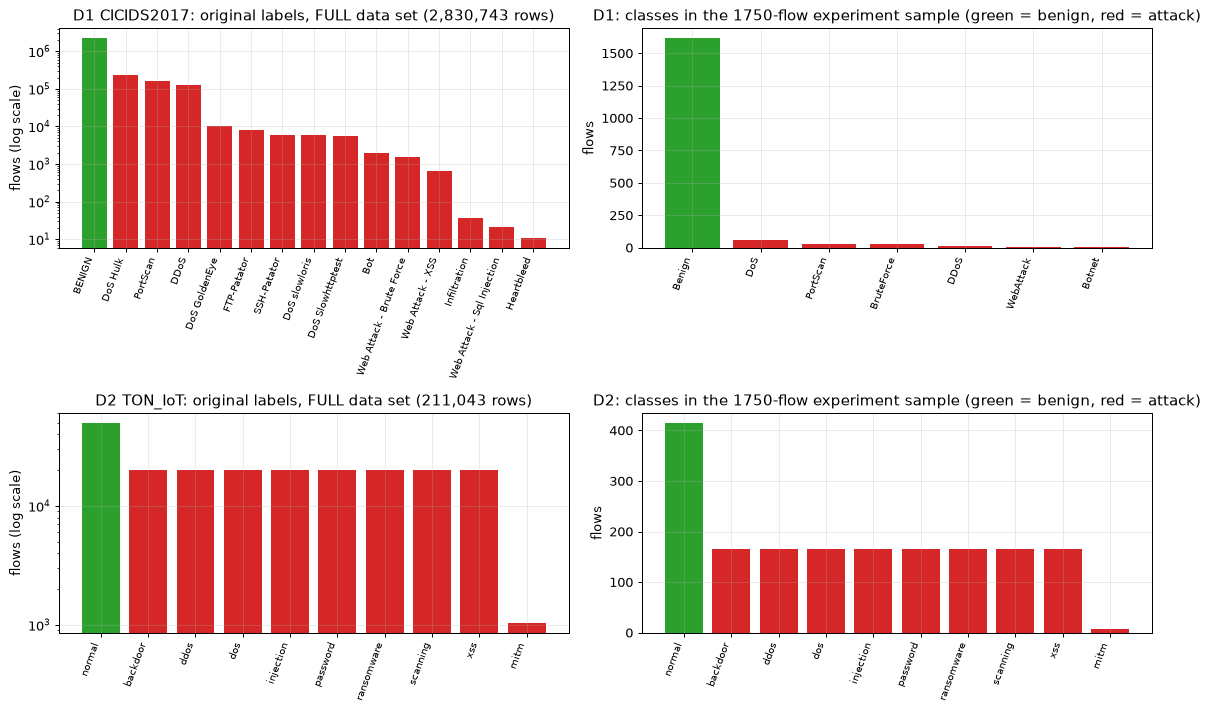

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for r, (k, d) in enumerate(D.items()):
    full = pd.Series(d["raw_label_counts"]).sort_values(ascending=False)
    axes[r, 0].bar(range(len(full)), full.values, color=["tab:green" if str(n).lower() in ("benign", "normal") else "tab:red" for n in full.index])
    axes[r, 0].set_yscale("log"); axes[r, 0].set_xticks(range(len(full))); axes[r, 0].set_xticklabels(full.index, rotation=70, ha="right", fontsize=8)
    axes[r, 0].set_title(f"{k} {d['name'][3:]}: original labels, FULL data set ({d['raw_rows']:,} rows)"); axes[r, 0].set_ylabel("flows (log scale)")
    smp = pd.Series(d["fam"]).value_counts()
    axes[r, 1].bar(range(len(smp)), smp.values, color=["tab:green" if str(n).lower() in ("benign", "normal") else "tab:red" for n in smp.index])
    axes[r, 1].set_xticks(range(len(smp))); axes[r, 1].set_xticklabels(smp.index, rotation=70, ha="right", fontsize=8)
    axes[r, 1].set_title(f"{k}: classes in the {len(d['y'])}-flow experiment sample (green = benign, red = attack)"); axes[r, 1].set_ylabel("flows")
plt.tight_layout(); plt.show()

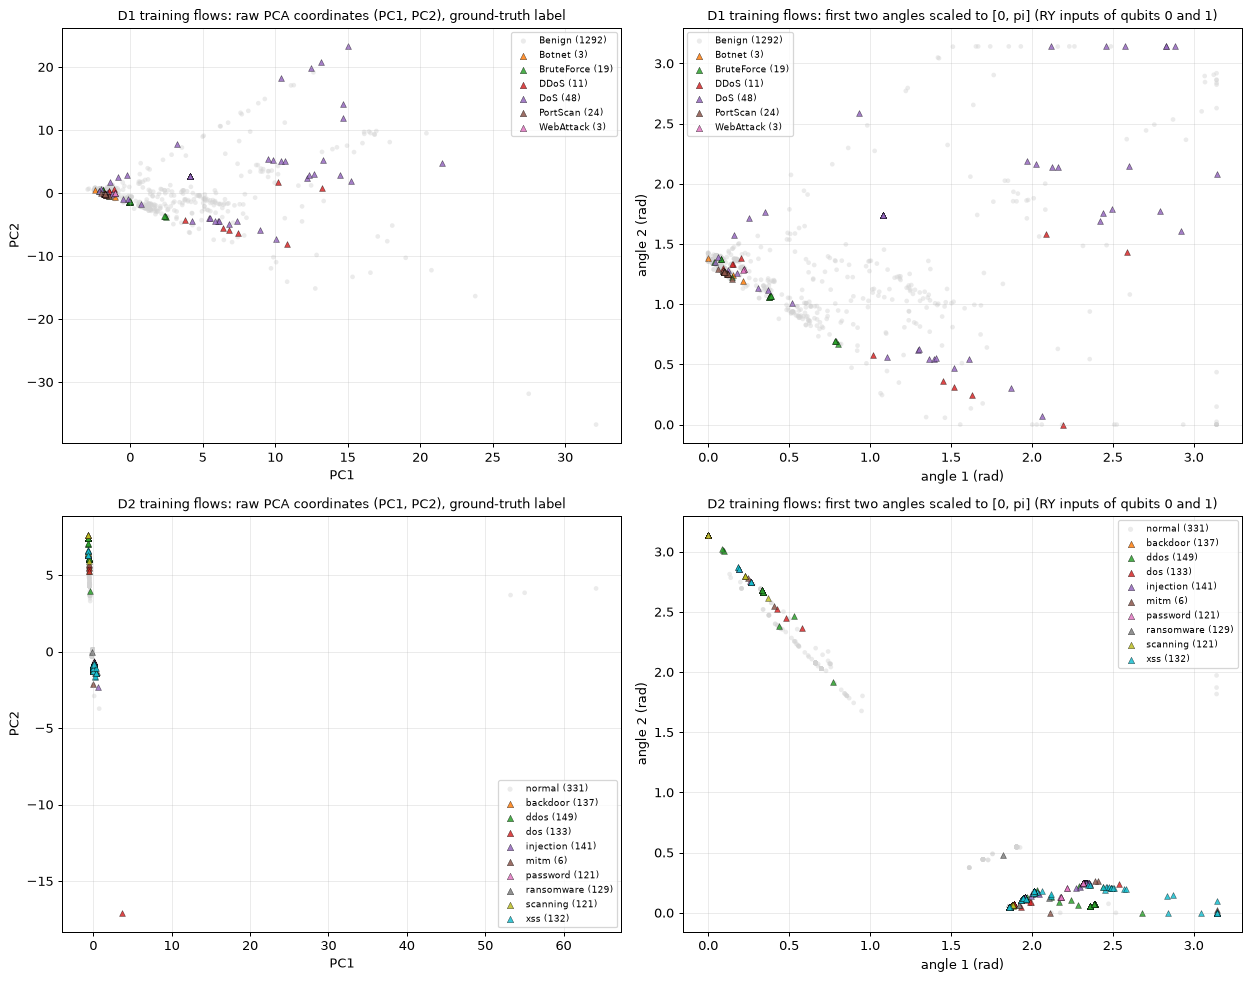

In [9]:
def scatter_by_label(ax, xy, labels, title, xlabel, ylabel):
    names = sorted(pd.unique(labels), key=lambda s: (str(s).lower() not in ("benign", "normal"), str(s)))
    cmap = plt.get_cmap("tab10")
    for i, n in enumerate(names):
        mk = labels == n
        benign = str(n).lower() in ("benign", "normal")
        ax.scatter(xy[mk, 0], xy[mk, 1], s=14 if benign else 22, alpha=0.45 if benign else 0.85, color="lightgrey" if benign else cmap(i % 10),
                   marker="o" if benign else "^", edgecolor="k" if not benign else "none", linewidth=0.3, label=f"{n} ({mk.sum()})")
    ax.set_title(title, fontsize=10); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.legend(fontsize=7, loc="best", markerscale=1.1)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for r, (k, d) in enumerate(D.items()):
    s = SP[k]; tr = s["tr"]
    scatter_by_label(axes[r, 0], s["P"][tr][:, :2], d["fam"][tr], f"{k} training flows: raw PCA coordinates (PC1, PC2), ground-truth label", "PC1", "PC2")
    scatter_by_label(axes[r, 1], s["A"][tr][:, :2], d["fam"][tr], f"{k} training flows: first two angles scaled to [0, pi] (RY inputs of qubits 0 and 1)", "angle 1 (rad)", "angle 2 (rad)")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Two distinct gate-based models are used and both are drawn from the **QNode objects that are actually executed** (`qml.draw_mpl`):

1. **QNN circuit** (`qnn_circuit`): `AngleEmbedding(RY)` on 13 qubits -> 7 `StronglyEntanglingLayers` (each: one `Rot(phi, theta, omega)` per qubit followed by a ring of 13 CNOTs, `ranges = 1`) -> `<Z>` on every qubit. The 13 expectation values feed a classical `Linear(13, 1)` layer (14 parameters), which is trained jointly with the 273 circuit angles.
2. **QSVM kernel circuit** (`kernel_circuit`): `AngleEmbedding(x)` followed by the adjoint embedding of `x'`; the kernel value is the probability of the all-zero outcome (paper Fig. 4, Eq. 3). It has no trainable parameters; the SVM dual coefficients are the only fitted quantities. To run 1,000 x 1,000 kernel entries quickly the Gram matrix is computed from the PennyLane **state vectors** of the embedding (`qml.state()`), and the cell below *asserts* that this equals the probabilities of the drawn kernel circuit.

Assumptions where the paper omits circuit details: the paper's Eq. (1) writes `RZ RY RX` rotations while its Fig. 3 shows a general rotation `R(alpha, beta, gamma)`; PennyLane's `Rot = RZ RY RZ` is used. The CNOT ring uses range 1 (nearest neighbour, last qubit connected to the first). Measurement is `<Z_i>` on all qubits (Eq. 2); the output is a single logit through a dense layer (Fig. 2).

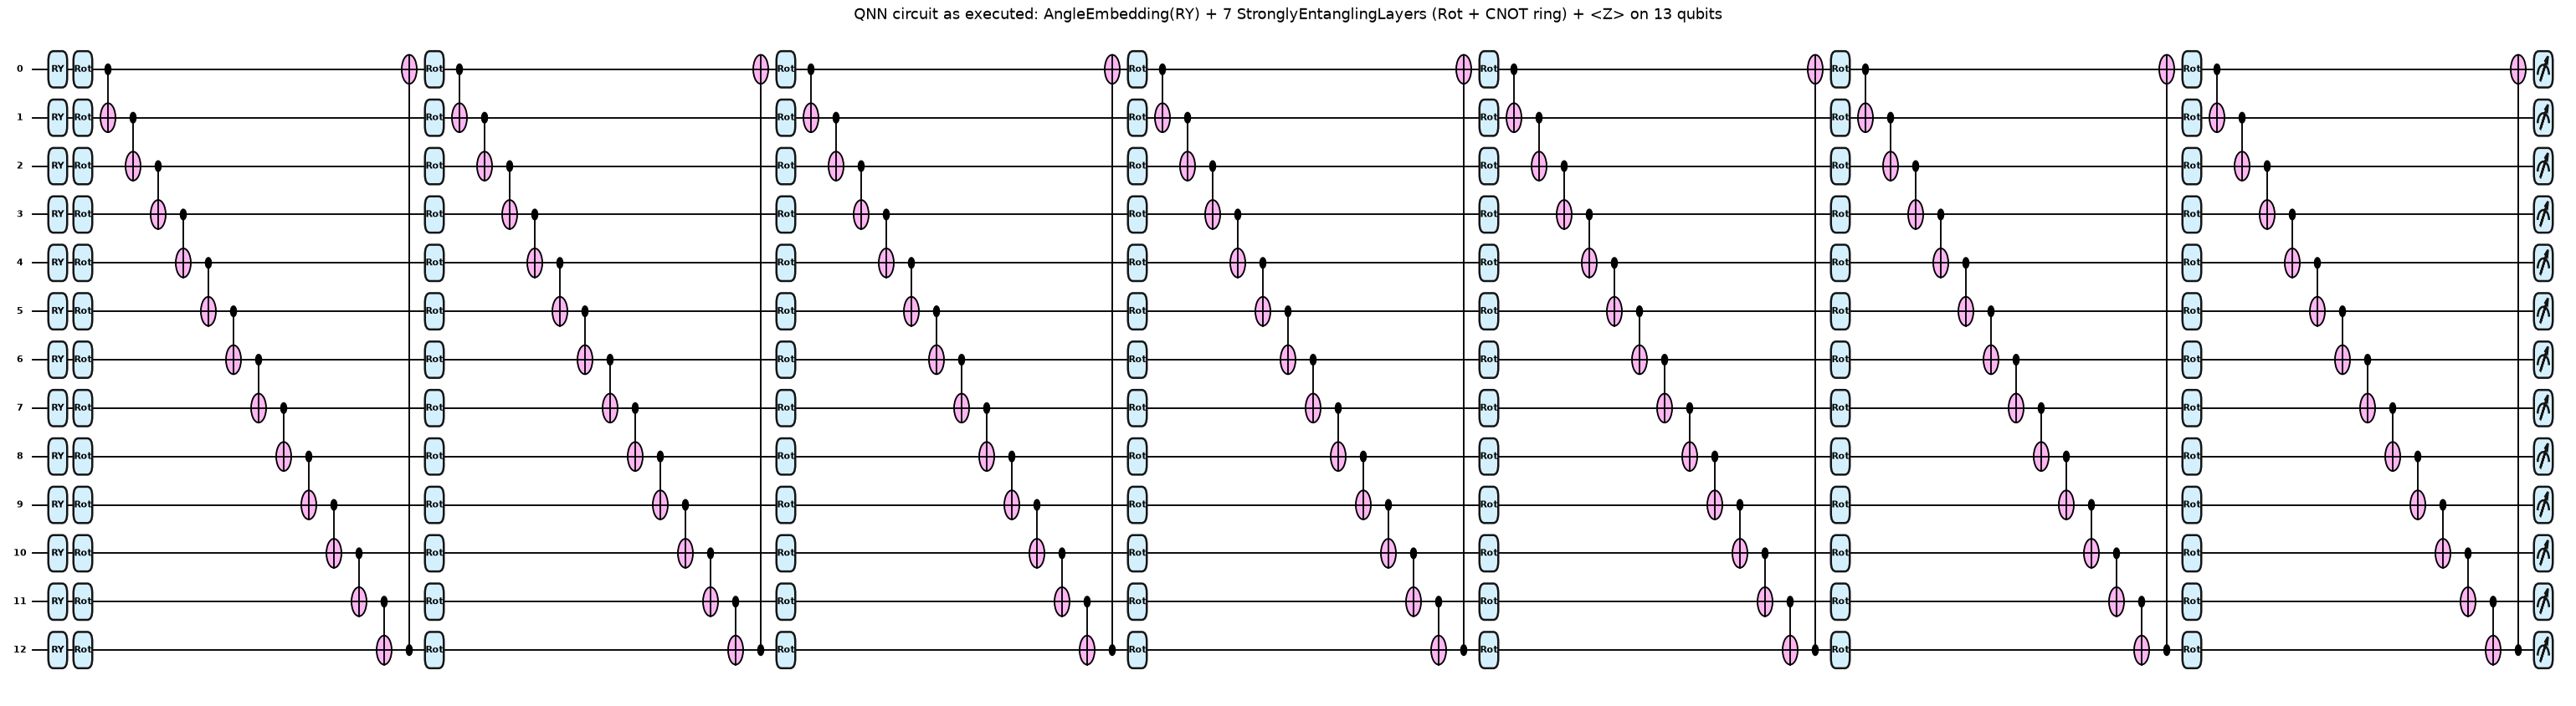

In [10]:
dev_qnn = qml.device("default.qubit", wires=N_QUBITS)                 # CHOICE: paper uses lightning.qubit; same circuit, faster gradients here
RANGES = [1] * N_LAYERS                                                # CNOT ring with nearest-neighbour range

@qml.qnode(dev_qnn, interface="torch", diff_method="backprop")
def qnn_circuit(x, weights):
    qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation="Y")        # |psi(x)> = (x) RY(x_i)|0>
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS), ranges=RANGES)
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

dev_k = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev_k)
def embed_state(x):
    qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation="Y")
    return qml.state()

@qml.qnode(dev_k)
def kernel_circuit(x1, x2):
    qml.AngleEmbedding(x1, wires=range(N_QUBITS), rotation="Y")                   # U(x1)
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(N_QUBITS), rotation="Y")      # U^dagger(x2)
    return qml.probs(wires=range(N_QUBITS))                                       # K = P(0...0)

x_demo = SP["D2"]["A"][0]
th_demo = torch.randn(N_LAYERS, N_QUBITS, 3, dtype=torch.float64) * QNN_INIT_STD
fig, ax = qml.draw_mpl(qnn_circuit, decimals=None, style="pennylane", fontsize=9, level="device")(torch.tensor(x_demo), th_demo)
fig.set_size_inches(34, 9); fig.suptitle("QNN circuit as executed: AngleEmbedding(RY) + 7 StronglyEntanglingLayers (Rot + CNOT ring) + <Z> on 13 qubits", fontsize=14, y=1.02)
plt.show()

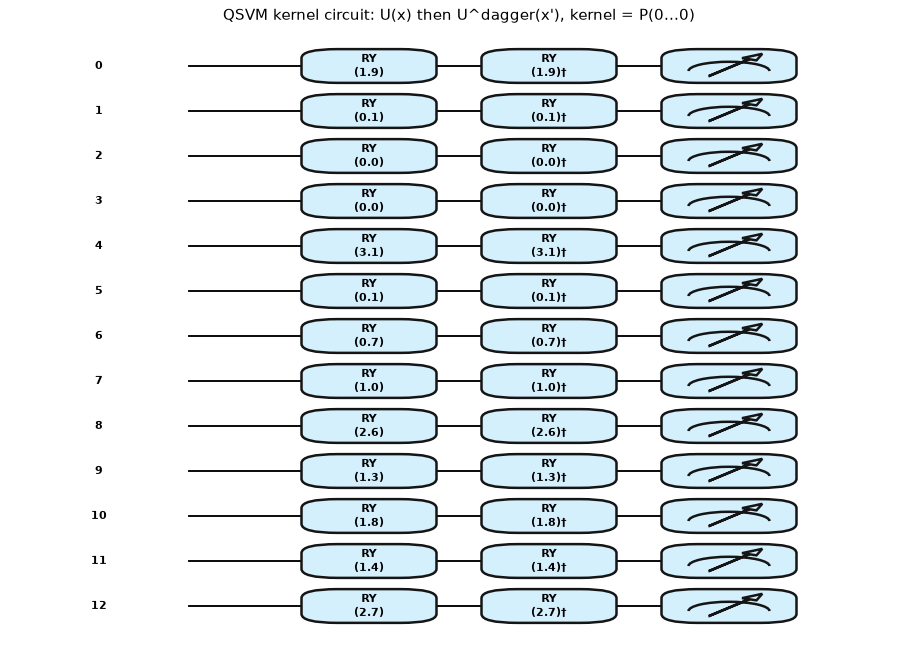

QNN circuit : qubits = 13, depth (after device compilation) = 99, gates = 195, gate types = {'RY': 13, 'Rot': 91, 'CNOT': 91}
              trainable parameters = 273 circuit angles (7 layers x 13 qubits x 3) + 14 dense-layer weights/bias = 287
Kernel circuit: qubits = 13, depth = 2, gates = 26, gate types = {'RY': 13, 'Adjoint(RY)': 13}, trainable circuit parameters = 0


assert OK: state-vector Gram matrix == P(0...0) of the drawn kernel circuit == prod_i cos^2((x_i - x'_i)/2)


In [11]:
fig, ax = qml.draw_mpl(kernel_circuit, decimals=1, style="pennylane", fontsize=9, level="device")(x_demo, SP["D2"]["A"][1])
fig.set_size_inches(10, 7); fig.suptitle("QSVM kernel circuit: U(x) then U^dagger(x'), kernel = P(0...0)", fontsize=12, y=1.02)
plt.show()

# ---------- circuit statistics from the executed QNodes
sp = qml.specs(qnn_circuit, level="device")(torch.tensor(x_demo), th_demo)
res = sp["resources"]
n_theta = int(th_demo.numel()); n_head = N_QUBITS + 1
print(f"QNN circuit : qubits = {N_QUBITS}, depth (after device compilation) = {res.depth}, gates = {res.num_gates}, gate types = {dict(res.gate_types)}")
print(f"              trainable parameters = {n_theta} circuit angles ({N_LAYERS} layers x {N_QUBITS} qubits x 3) + {n_head} dense-layer weights/bias = {n_theta + n_head}")
spk = qml.specs(kernel_circuit, level="device")(x_demo, SP["D2"]["A"][1])["resources"]
print(f"Kernel circuit: qubits = {N_QUBITS}, depth = {spk.depth}, gates = {spk.num_gates}, gate types = {dict(spk.gate_types)}, trainable circuit parameters = 0")

# ---------- state-vector Gram matrix == probability of |0..0> in the drawn kernel circuit
def states(A, chunk=200):
    out = []
    for i in range(0, len(A), chunk):
        out.append(np.asarray(embed_state(np.asarray(A[i:i + chunk], dtype=float))))
    return np.concatenate(out)

def gram(Sa, Sb, chunk=400):
    G = np.empty((len(Sa), len(Sb)))
    for i in range(0, len(Sa), chunk):
        G[i:i + chunk] = np.abs(Sa[i:i + chunk].conj() @ Sb.T) ** 2
    return G

Atest = SP["D2"]["A"][:6]
Gs = gram(states(Atest), states(Atest))
Gc = np.array([[float(np.asarray(kernel_circuit(Atest[i], Atest[j]))[0]) for j in range(6)] for i in range(6)])
assert np.allclose(Gs, Gc, atol=1e-10), "state-vector Gram matrix differs from the kernel circuit"
assert np.allclose(Gs, np.array([[np.prod(np.cos((Atest[i] - Atest[j]) / 2) ** 2) for j in range(6)] for i in range(6)]), atol=1e-10)
print("assert OK: state-vector Gram matrix == P(0...0) of the drawn kernel circuit == prod_i cos^2((x_i - x'_i)/2)")

## 3. Metrics (paper Section III-F)

Accuracy, precision, recall, F1 (attack = positive class), AUPRC, ROC-AUC, TPR at 0.1 % and 1 % FPR (largest TPR on the ROC curve whose FPR does not exceed the threshold), Brier score and Expected Calibration Error with 15 equal-width bins (Eq. 8 and 9). With about 320 benign test flows, a 0.1 % FPR means *zero* false alarms, so TPR@0.1%FPR is very noisy here.

In [12]:
def tpr_at_fpr(y, s, fpr_t):
    fpr, tpr, _ = roc_curve(y, s)
    return 100 * tpr[fpr <= fpr_t].max()

def ece_score(y, p, bins=15):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1); e = 0.0
    for b in range(bins):
        mk = idx == b
        if mk.any():
            e += mk.mean() * abs(y[mk].mean() - p[mk].mean())
    return e

def evaluate(y, score, pred):
    return dict(Acc=100 * accuracy_score(y, pred), Prec=100 * precision_score(y, pred, zero_division=0), Rec=100 * recall_score(y, pred, zero_division=0),
                F1=100 * f1_score(y, pred, zero_division=0), AUPRC=100 * average_precision_score(y, score), ROC_AUC=roc_auc_score(y, score),
                TPR01=tpr_at_fpr(y, score, 0.001), TPR1=tpr_at_fpr(y, score, 0.01), Brier=100 * brier_score_loss(y, score), ECE=100 * ece_score(y, score))

PAPER_VI = {   # paper Table VI: (Acc, F1, AUPRC, ROC AUC, TPR@0.1%FPR, TPR@1%FPR); D2 AUPRC of RF/XGB printed as "~100"
 "D1": {"RandomForest": (99.73, 98.29, 99.80, 0.9998, 97.24, 99.08), "XGBoost": (99.78, 98.61, 99.73, 0.9996, 98.16, 99.08), "LogReg": (95.50, 63.27, 66.80, 0.9178, 46.01, 49.08),
        "QNN Base": (97.10, 77.86, 89.47, 0.9781, 47.44, 80.77), "QSVM": (95.10, 62.60, 68.59, 0.9130, 15.38, 47.44),
        "MQE Probability": (97.14, 81.48, 86.23, 0.9674, 40.74, 70.37), "MQE Margin": (96.86, 78.43, 83.93, 0.9442, 44.44, 74.07), "MQE Hard": (96.29, 69.77, 62.86, 0.8122, 35.50, 62.99)},
 "D2": {"RandomForest": (99.97, 99.98, 100.0, 1.0000, 99.99, 100.00), "XGBoost": (99.96, 99.97, 100.0, 1.0000, 99.98, 100.00), "LogReg": (95.24, 96.90, 95.92, 0.9554, 0.29, 0.59),
        "QNN Base": (98.70, 99.13, 99.82, 0.9952, 59.62, 89.10), "QSVM": (97.00, 98.00, 99.20, 0.9916, 0.54, 93.81),
        "MQE Probability": (98.57, 99.05, 99.55, 0.9933, 7.89, 78.92), "MQE Margin": (98.57, 99.04, 99.54, 0.9932, 7.75, 77.54), "MQE Hard": (99.14, 99.43, 99.61, 0.9943, 8.93, 89.31)},
}
RES = {k: {} for k in D}        # RES[dataset][model] = dict of metrics on the test split
SCORES = {k: {} for k in D}     # SCORES[dataset][model] = (score, predicted label) on the test split
def store(k, name, y_te, score, pred):
    RES[k][name] = evaluate(y_te, score, pred); SCORES[k][name] = (np.asarray(score), np.asarray(pred))

## 4. Classical baselines on identical inputs

Random Forest, XGBoost and logistic regression receive exactly the 13 angle features that the quantum models receive and are fitted on the whole training split (paper Table VI "classical baselines").

In [13]:
def fit_classical(A, y, tr, seed):
    models = {"RandomForest": RandomForestClassifier(n_estimators=RF_TREES, random_state=seed, n_jobs=2),
              "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, eval_metric="logloss", random_state=seed, n_jobs=2),
              "LogReg": LogisticRegression(max_iter=2000, random_state=seed)}
    return {n: m.fit(A[tr], y[tr]) for n, m in models.items()}

for k in D:
    s, y = SP[k], D[k]["y"]
    t0 = time.time(); fitted = fit_classical(s["A"], y, s["tr"], SEED)
    for n, m in fitted.items():
        store(k, n, y[s["te"]], m.predict_proba(s["A"][s["te"]])[:, 1], m.predict(s["A"][s["te"]]))
    print(k, "classical baselines done in", round(time.time() - t0, 1), "s")

D1 classical baselines done in 6.5 s


D2 classical baselines done in 4.6 s


## 5. QSVM branch

The exact fidelity kernel is computed between all pairs of PennyLane embedding states, the SVM (`C = 10`) is fitted on the **base part** of the training split, and its label, its signed distance to the hyperplane (the "margin") and a Platt-scaled attack probability are returned for the meta part and the test split. The extra row *QSVM (tuned scale)* multiplies all angles by a factor chosen by 3-fold cross-validation inside the base part (a kernel bandwidth, never looking at the test split); it is **not** used by the ensemble, which stays paper-literal.

In [14]:
def qsvm_branch(A, y, sp, scale=1.0, seed=SEED):
    S = states(A * scale)
    b, m, te = sp["b"], sp["m"], sp["te"]
    Gbb, Gmb, Gtb = gram(S[b], S[b]), gram(S[m], S[b]), gram(S[te], S[b]); del S
    svc = SVC(kernel="precomputed", C=QSVM_C, probability=True, random_state=seed).fit(Gbb, y[b])
    out = {}
    for name, G in (("m", Gmb), ("te", Gtb)):
        out[name] = dict(label=svc.predict(G), dec=svc.decision_function(G), prob=svc.predict_proba(G)[:, 1])
    return out, Gbb

QS, QS_TIME = {}, {}
for k in D:
    s, y = SP[k], D[k]["y"]
    t0 = time.time(); QS[k], Gbb = qsvm_branch(s["A"], y, s); QS_TIME[k] = time.time() - t0
    o = QS[k]["te"]; store(k, "QSVM", y[s["te"]], o["prob"], o["label"])
    # extra row: kernel scale tuned inside the base part (3-fold CV, F1)
    cv = StratifiedKFold(3, shuffle=True, random_state=SEED); cvres = {}
    for sc_ in QSVM_SCALES:
        G = Gbb if sc_ == 1.0 else gram(states(s["A"][s["b"]] * sc_), states(s["A"][s["b"]] * sc_))
        cvres[sc_] = cross_val_score(SVC(kernel="precomputed", C=QSVM_C), G, y[s["b"]], cv=cv, scoring="f1").mean()
    best = max(cvres, key=cvres.get)
    q2, _ = qsvm_branch(s["A"], y, s, scale=best); o2 = q2["te"]
    store(k, "QSVM (tuned scale)", y[s["te"]], o2["prob"], o2["label"])
    print(f"{k}: QSVM kernel+SVM {QS_TIME[k]:.1f} s | CV F1 per angle scale {({a: round(v, 3) for a, v in cvres.items()})} -> best scale {best} | "
          f"test F1 paper-literal {RES[k]['QSVM']['F1']:.2f}, tuned {RES[k]['QSVM (tuned scale)']['F1']:.2f}")

D1: QSVM kernel+SVM 30.7 s | CV F1 per angle scale {0.25: np.float64(0.515), 0.5: np.float64(0.598), 1.0: np.float64(0.667)} -> best scale 1.0 | test F1 paper-literal 71.11, tuned 71.11


D2: QSVM kernel+SVM 26.8 s | CV F1 per angle scale {0.25: np.float64(0.947), 0.5: np.float64(0.962), 1.0: np.float64(0.97)} -> best scale 1.0 | test F1 paper-literal 97.78, tuned 97.78


## 6. QNN branch (the slow part)

The variational circuit is trained with Adam on the base part of the training split, jointly with the dense output layer (`Linear(13, 1)`, binary cross-entropy on the logit = the two-class cross-entropy of Table I). Training uses mini-batches of 32 flows; the PennyLane QNode is called with a whole batch (parameter broadcasting) and differentiated by back-propagation through the simulator.

**Budget.** The paper trains for 100+ epochs on a GPU machine; a 13-qubit, 273-angle circuit costs several seconds per mini-batch on a shared laptop CPU, so the number of epochs is cut (see the configuration cell) and a wall-clock cap stops the training of each dataset when its budget is used up. The monitoring accuracy (Fig. 5 analogue) is computed on the meta part and is **not** used for early stopping or model selection.

In [15]:
import torch.nn.functional as F

def qnn_logits(head, theta, A, chunk=64):
    out = []
    with torch.no_grad():
        for i in range(0, len(A), chunk):
            z = torch.stack(qnn_circuit(torch.tensor(A[i:i + chunk]), theta), dim=-1)
            out.append(head(z).squeeze(-1).numpy())
    return np.concatenate(out)

def train_qnn(key, sp, seed=SEED, epochs=QNN_EPOCHS, lr=QNN_LR, batch=QNN_BATCH, cap=QNN_TIME_CAP_S):
    A, y = sp["A"], D[key]["y"]
    torch.manual_seed(seed); gen = np.random.default_rng(seed)
    theta = (QNN_INIT_STD * torch.randn(N_LAYERS, N_QUBITS, 3, dtype=torch.float64)).requires_grad_()   # CHOICE: small initial angles
    head = torch.nn.Linear(N_QUBITS, 1).double()
    opt = torch.optim.Adam([theta] + list(head.parameters()), lr=lr)
    yb_all = y[sp["b"]]; n_pos, n_neg = max(yb_all.sum(), 1), max((1 - yb_all).sum(), 1)
    pw = torch.tensor(math.sqrt(n_neg / n_pos), dtype=torch.float64) if QNN_POS_WEIGHT == "sqrt" else None
    hist, t0, stop = [], time.time(), False
    for ep in range(epochs):
        perm = gen.permutation(sp["b"]); tl, tc, tn = 0.0, 0, 0
        for i in range(0, len(perm), batch):
            ib = perm[i:i + batch]
            if len(ib) < 2: continue
            z = torch.stack(qnn_circuit(torch.tensor(A[ib]), theta), dim=-1)
            logit = head(z).squeeze(-1); tgt = torch.tensor(y[ib], dtype=torch.float64)
            loss = F.binary_cross_entropy_with_logits(logit, tgt, pos_weight=pw)
            opt.zero_grad(); loss.backward(); opt.step()
            tl += loss.item() * len(ib); tc += int(((logit.detach() > 0).numpy() == y[ib]).sum()); tn += len(ib)
            if time.time() - t0 > cap: stop = True; break
        mon = qnn_logits(head, theta, A[sp["m"]]); mon_acc = float(((mon > 0) == y[sp["m"]]).mean())
        hist.append(dict(epoch=ep + 1, loss=tl / tn, train_acc=tc / tn, monitor_acc=mon_acc, seconds=time.time() - t0))
        print(f"  {key} epoch {ep + 1}/{epochs}: loss {tl / tn:.4f} | train acc {tc / tn:.3f} | meta-part acc {mon_acc:.3f} | {time.time() - t0:.0f} s" + ("  (time cap reached)" if stop else ""), flush=True)
        if stop: break
    return head, theta, pd.DataFrame(hist)

QN, QN_HIST, QN_TIME = {}, {}, {}
for k in D:
    s, y = SP[k], D[k]["y"]
    t0 = time.time(); head, theta, hist = train_qnn(k, s)
    lm, lt = qnn_logits(head, theta, s["A"][s["m"]]), qnn_logits(head, theta, s["A"][s["te"]])
    QN[k] = dict(m=dict(logit=lm, prob=1 / (1 + np.exp(-lm)), label=(lm > 0).astype(int)), te=dict(logit=lt, prob=1 / (1 + np.exp(-lt)), label=(lt > 0).astype(int)), theta=theta, head=head)
    QN_HIST[k], QN_TIME[k] = hist, time.time() - t0
    store(k, "QNN Base", y[s["te"]], QN[k]["te"]["prob"], QN[k]["te"]["label"])
    print(f"{k}: QNN trained {len(hist)} epoch(s) + predictions in {QN_TIME[k]:.0f} s | test F1 {RES[k]['QNN Base']['F1']:.2f}, acc {RES[k]['QNN Base']['Acc']:.2f}")

  D1 epoch 1/12: loss 0.6765 | train acc 0.760 | meta-part acc 0.923 | 219 s


  D1 epoch 2/12: loss 0.5183 | train acc 0.931 | meta-part acc 0.926 | 549 s


  D1 epoch 3/12: loss 0.4683 | train acc 0.928 | meta-part acc 0.929 | 804 s


  D1 epoch 4/12: loss 0.4407 | train acc 0.929 | meta-part acc 0.943 | 990 s


  D1 epoch 5/12: loss 0.4256 | train acc 0.926 | meta-part acc 0.946 | 1199 s


...

  D2 epoch 2/12: loss 0.3046 | train acc 0.848 | meta-part acc 0.860 | 630 s


  D2 epoch 3/12: loss 0.2631 | train acc 0.860 | meta-part acc 0.914 | 874 s


  D2 epoch 4/12: loss 0.2571 | train acc 0.872 | meta-part acc 0.914 | 1354 s


  D2 epoch 5/12: loss 0.2421 | train acc 0.900 | meta-part acc 0.926 | 1901 s  (time cap reached)


D2: QNN trained 5 epoch(s) + predictions in 1993 s | test F1 94.10, acc 90.86


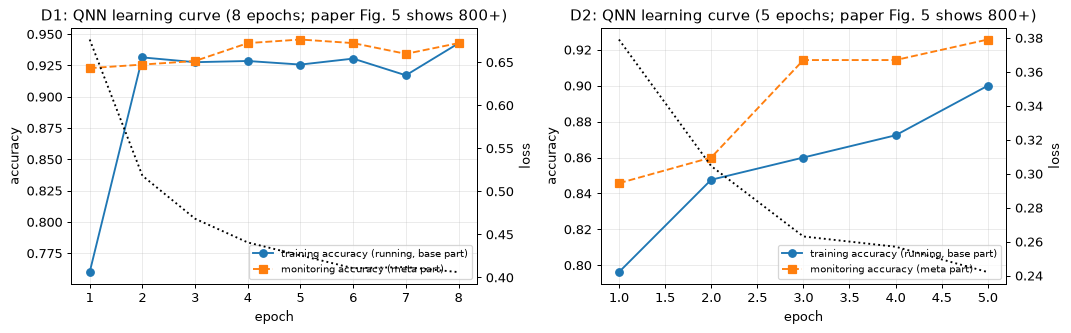

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (k, h) in zip(axes, QN_HIST.items()):
    ax.plot(h["epoch"], h["train_acc"], "o-", label="training accuracy (running, base part)")
    ax.plot(h["epoch"], h["monitor_acc"], "s--", label="monitoring accuracy (meta part)")
    ax2 = ax.twinx(); ax2.plot(h["epoch"], h["loss"], "k:", label="training loss"); ax2.set_ylabel("loss"); ax2.grid(False)
    ax.set_title(f"{k}: QNN learning curve ({len(h)} epochs; paper Fig. 5 shows 800+)"); ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 7. The Meta-Quantum Ensemble

The Random Forest (100 trees, Gini, unrestricted depth) is fitted on the **meta part** of the training split, using the outputs of the two quantum branches for those rows, and applied to the test split. Three meta-feature representations (paper Section IV-C):

* **Hard**: `[QSVM label, QNN label]`
* **Margin**: `[SVM decision value, QNN logit]`
* **Probability**: `[QNN attack probability, QSVM attack probability]` (Eq. 6)

In [17]:
def meta_features(kind, q, n):
    if kind == "Hard":        return np.c_[q["label"], n["label"]].astype(float)
    if kind == "Margin":      return np.c_[q["dec"], n["logit"]]
    if kind == "Probability": return np.c_[n["prob"], q["prob"]]

META = {}
for k in D:
    s, y = SP[k], D[k]["y"]; META[k] = {}
    for kind in ("Probability", "Margin", "Hard"):
        rf = RandomForestClassifier(n_estimators=RF_TREES, criterion="gini", max_depth=None, random_state=SEED, n_jobs=2)
        rf.fit(meta_features(kind, QS[k]["m"], QN[k]["m"]), y[s["m"]])
        Fte = meta_features(kind, QS[k]["te"], QN[k]["te"])
        prob, pred = rf.predict_proba(Fte)[:, 1], rf.predict(Fte)
        META[k][kind] = rf; store(k, f"MQE {kind}", y[s["te"]], prob, pred)
    print(k, "meta-learners fitted on", len(s["m"]), "meta-part flows (", int(y[s["m"]].sum()), "attacks )")

D1 meta-learners fitted on 350 meta-part flows ( 27 attacks )


D2 meta-learners fitted on 350 meta-part flows ( 267 attacks )


## 8. Results: paper Table VI re-computed (test split, seed 42)

For every model the notebook value is shown first and the paper's value below it (`paper`). Accuracy, F1, AUPRC and the TPR columns are in percent.

In [18]:
ORDER = ["RandomForest", "XGBoost", "LogReg", "QNN Base", "QSVM", "QSVM (tuned scale)", "MQE Probability", "MQE Margin", "MQE Hard"]
COLS = ["Acc", "F1", "AUPRC", "ROC_AUC", "TPR01", "TPR1"]
pd.set_option("display.width", 220)
TABLES = {}
for k in D:
    rows = []
    for n in ORDER:
        r = RES[k][n]; rows.append(dict(model=n, source="notebook", **{c: r[c] for c in COLS}))
        if n in PAPER_VI[k]:
            rows.append(dict(model=n, source="paper", **dict(zip(COLS, PAPER_VI[k][n]))))
    TABLES[k] = pd.DataFrame(rows)
    print(f"\n{k} = {D[k]['name']} (test flows: {len(SP[k]['te'])}, attacks: {int(D[k]['y'][SP[k]['te']].sum())})")
    print(TABLES[k].round(2).to_string(index=False))


D1 = D1 CICIDS2017 (test flows: 350, attacks: 27)
             model   source   Acc    F1  AUPRC  ROC_AUC  TPR01  TPR1
      RandomForest notebook 97.71 84.62  91.52     0.99  70.37 81.48
      RandomForest    paper 99.73 98.29  99.80     1.00  97.24 99.08
           XGBoost notebook 98.00 86.27  92.78     0.99  59.26 81.48
           XGBoost    paper 99.78 98.61  99.73     1.00  98.16 99.08
            LogReg notebook 94.00 40.00  44.61     0.80  18.52 25.93
            LogReg    paper 95.50 63.27  66.80     0.92  46.01 49.08
          QNN Base notebook 94.00 48.78  52.09     0.87  18.52 37.04
          QNN Base    paper 97.10 77.86  89.47     0.98  47.44 80.77
              QSVM notebook 96.29 71.11  76.16     0.94  11.11 59.26
              QSVM    paper 95.10 62.60  68.59     0.91  15.38 47.44
QSVM (tuned scale) notebook 96.29 71.11  76.16     0.94  11.11 59.26
   MQE Probability notebook 95.43 71.43  77.76     0.92  37.04 66.67
   MQE Probability    paper 97.14 81.48  86.23     0

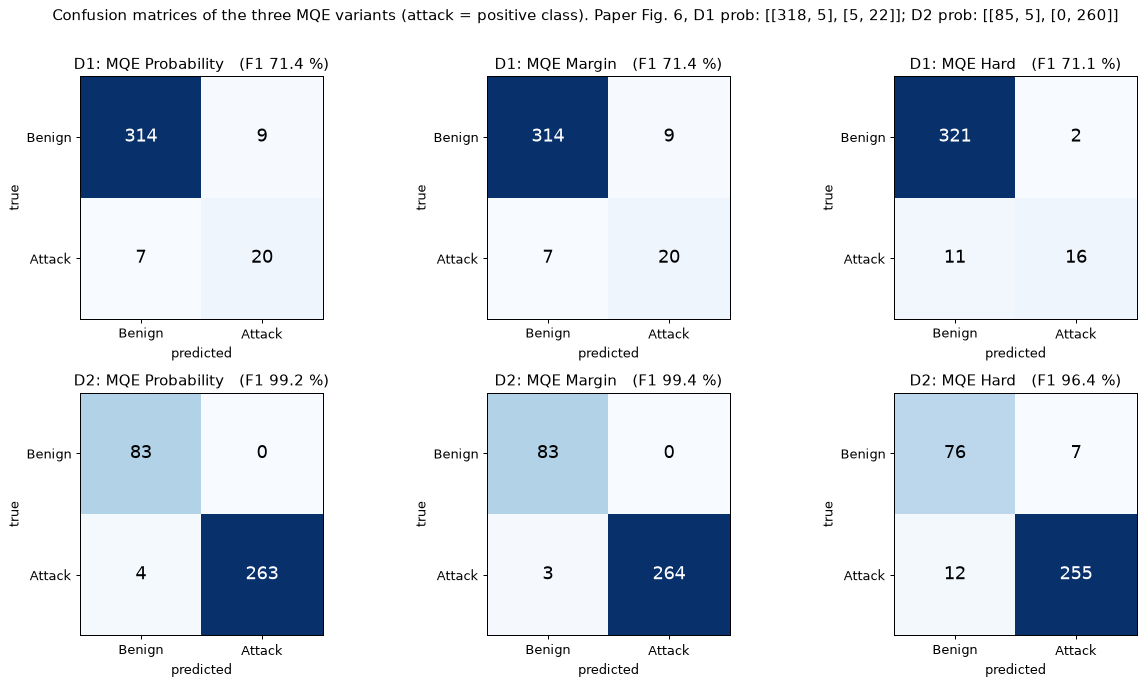

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for r, k in enumerate(D):
    y_te = D[k]["y"][SP[k]["te"]]
    for c, kind in enumerate(("MQE Probability", "MQE Margin", "MQE Hard")):
        cm = confusion_matrix(y_te, SCORES[k][kind][1], labels=[0, 1]); ax = axes[r, c]
        ax.imshow(cm, cmap="Blues"); ax.grid(False)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Benign", "Attack"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Benign", "Attack"])
        ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{k}: {kind}   (F1 {RES[k][kind]['F1']:.1f} %)")
plt.suptitle("Confusion matrices of the three MQE variants (attack = positive class). Paper Fig. 6, D1 prob: [[318, 5], [5, 22]]; D2 prob: [[85, 5], [0, 260]]", y=1.01)
plt.tight_layout(); plt.show()

## 9. Meta-fusion analysis, calibration (paper Table III, Table V, Fig. 7, Fig. 9)

* **Error sets and disagreement rate** of the two quantum branches on the test split (decision threshold 0.5): who is wrong, who is wrong together, how often do their labels differ.
* **Brier score and ECE** (15 bins) of the probability-fusion MQE, and its reliability diagram.

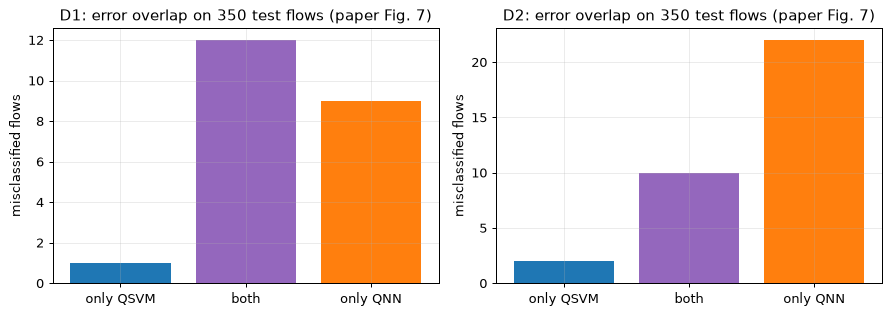

dataset  QSVM_errors  QNN_errors  both  only_QSVM  only_QNN  disagreement_pct  test_flows
     D1           13          21    12          1         9              2.86         350
     D2           12          32    10          2        22              6.86         350
paper Table III: {'D1': {'QSVM': 97, 'QNN': 62, 'Both': 46, 'Disagree': 6.7}, 'D2': {'QSVM': 28, 'QNN': 7, 'Both': 4, 'Disagree': 2.7}}


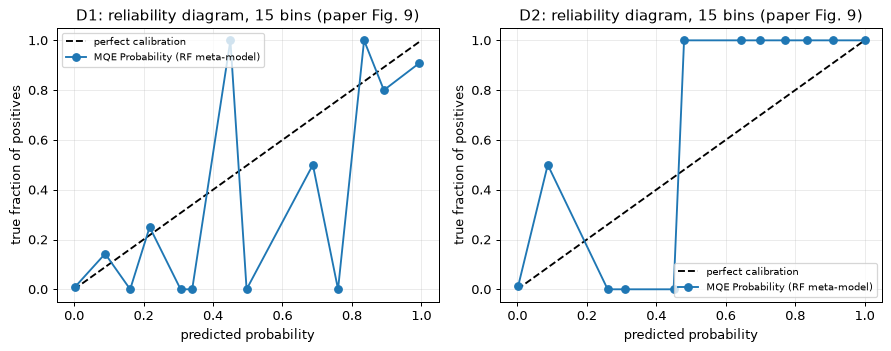

Brier (%) / ECE (%) of MQE Probability, notebook: {'D1': {'Brier': 3.42, 'ECE': np.float64(3.56)}, 'D2': {'Brier': 1.3, 'ECE': np.float64(2.5)}} | paper Table V: D1 6.07 / 0.16, D2 0.57 / 0.04


In [20]:
PAPER_III = {"D1": dict(QSVM=97, QNN=62, Both=46, Disagree=6.7), "D2": dict(QSVM=28, QNN=7, Both=4, Disagree=2.7)}
rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, k in zip(axes, D):
    y_te = D[k]["y"][SP[k]["te"]]; eq = QS[k]["te"]["label"] != y_te; en = QN[k]["te"]["label"] != y_te
    r = dict(dataset=k, QSVM_errors=int(eq.sum()), QNN_errors=int(en.sum()), both=int((eq & en).sum()), only_QSVM=int((eq & ~en).sum()), only_QNN=int((en & ~eq).sum()),
             disagreement_pct=100 * float((QS[k]["te"]["label"] != QN[k]["te"]["label"]).mean()), test_flows=len(y_te))
    rows.append(r)
    ax.bar(["only QSVM", "both", "only QNN"], [r["only_QSVM"], r["both"], r["only_QNN"]], color=["tab:blue", "tab:purple", "tab:orange"])
    ax.set_title(f"{k}: error overlap on {len(y_te)} test flows (paper Fig. 7)"); ax.set_ylabel("misclassified flows")
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).round(2).to_string(index=False))
print("paper Table III:", PAPER_III)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
CAL = {}
for ax, k in zip(axes, D):
    y_te = D[k]["y"][SP[k]["te"]]; p = SCORES[k]["MQE Probability"][0]
    edges = np.linspace(0, 1, 16); idx = np.clip(np.digitize(p, edges[1:-1]), 0, 14)
    xs = [p[idx == b].mean() for b in range(15) if (idx == b).any()]; ys = [y_te[idx == b].mean() for b in range(15) if (idx == b).any()]
    ax.plot([0, 1], [0, 1], "k--", label="perfect calibration"); ax.plot(xs, ys, "o-", label="MQE Probability (RF meta-model)")
    ax.set_title(f"{k}: reliability diagram, 15 bins (paper Fig. 9)"); ax.set_xlabel("predicted probability"); ax.set_ylabel("true fraction of positives"); ax.legend(fontsize=8)
    CAL[k] = dict(Brier=RES[k]["MQE Probability"]["Brier"], ECE=RES[k]["MQE Probability"]["ECE"])
plt.tight_layout(); plt.show()
print("Brier (%) / ECE (%) of MQE Probability, notebook:", {k: {a: round(b, 2) for a, b in v.items()} for k, v in CAL.items()}, "| paper Table V: D1 6.07 / 0.16, D2 0.57 / 0.04")

## 10. How stable is a 350-flow test set? Repeats over split seeds

The QNN is too slow to repeat, but QSVM and the three classical models are cheap. They are re-run with different split seeds (new train/test split, new PCA/angle scaling, new base/meta part; same sampled flows). With only about 27 attack flows in the D1 test set, the F1 of a single run moves by several points from seed to seed, which is the right yardstick for the 2-point tolerance used in the verdicts below.

In [21]:
REP = {k: {} for k in D}
for k in D:
    y = D[k]["y"]
    for seed in range(SEED, SEED + N_REPEAT_SEEDS):
        s = split_and_prepare(k, seed)
        qs, _ = qsvm_branch(s["A"], y, s, seed=seed); cl = fit_classical(s["A"], y, s["tr"], seed)
        res = {"QSVM": f1_score(y[s["te"]], qs["te"]["label"]) * 100}
        res.update({n: f1_score(y[s["te"]], m.predict(s["A"][s["te"]])) * 100 for n, m in cl.items()})
        for n, v in res.items(): REP[k].setdefault(n, []).append(v)
rep_rows = [dict(dataset=k, model=n, F1_mean=np.mean(v), F1_std=np.std(v), runs=len(v), paper_F1=PAPER_VI[k][n][1]) for k in D for n, v in REP[k].items()]
print(pd.DataFrame(rep_rows).round(2).to_string(index=False))

dataset        model  F1_mean  F1_std  runs  paper_F1
     D1         QSVM    74.58    3.38     3     62.60
     D1 RandomForest    85.14    2.52     3     98.29
     D1      XGBoost    83.38    3.00     3     98.61
     D1       LogReg    46.95    6.93     3     63.27
     D2         QSVM    97.19    0.84     3     98.00
     D2 RandomForest    99.13    0.32     3     99.98
     D2      XGBoost    99.06    0.40     3     99.97
     D2       LogReg    92.22    0.65     3     96.90


## 11. Side by side with the paper: verdict per claim

Rule (same for all claims): a value is **reproduced** if it is within 2 accuracy points / 2 F1 points of the paper (TPR columns: 10 points, because they are driven by a handful of flows), **exceeded** if it is higher by more, **not reached** if it is lower by more. Qualitative claims are checked directly on the notebook's numbers. What cannot be run here is marked **cannot be checked**.

In [22]:
V = []
def verdict(claim, paper, ours, tol, kind="higher"):
    # kind: "higher" = higher is better; "lower" = lower is better (Brier, ECE); "neutral" = a descriptive statistic
    d = ours - paper
    if abs(d) <= tol: v = "reproduced"
    elif kind == "neutral": v = "differs"
    elif (d > 0) == (kind == "higher"): v = "exceeded (better than paper)"
    else: v = "not reached"
    V.append(dict(claim=claim, paper=paper, notebook=round(ours, 2), gap=round(d, 2), verdict=v))
def qual(claim, paper_txt, ok, ours_txt):
    V.append(dict(claim=claim, paper=paper_txt, notebook=ours_txt, verdict="reproduced" if ok else "not reached"))

for k in D:
    for n in ("MQE Probability", "MQE Margin", "MQE Hard", "QNN Base", "QSVM", "RandomForest", "XGBoost", "LogReg"):
        p = PAPER_VI[k][n]; r = RES[k][n]
        verdict(f"{k} {n}: accuracy (%)", p[0], r["Acc"], 2); verdict(f"{k} {n}: F1 (%)", p[1], r["F1"], 2)
    for n in ("MQE Probability", "MQE Margin", "MQE Hard"):
        verdict(f"{k} {n}: TPR@1%FPR (%)", PAPER_VI[k][n][5], RES[k][n]["TPR1"], 10)
    Wm = {n: RES[k][n]["F1"] for n in ("MQE Probability", "MQE Margin", "MQE Hard")}
    qual(f"{k}: best MQE variant by F1 is " + ("Probability" if k == "D1" else "Hard"), "Probability (D1) / Hard (D2)", max(Wm, key=Wm.get) == ("MQE Probability" if k == "D1" else "MQE Hard"), max(Wm, key=Wm.get))
    qual(f"{k}: best MQE variant F1 > QSVM F1", "yes", max(Wm.values()) > RES[k]["QSVM"]["F1"], f"{max(Wm.values()):.1f} vs {RES[k]['QSVM']['F1']:.1f}")
    qual(f"{k}: best MQE variant F1 > QNN Base F1", "yes (D1 81.48 vs 77.86; D2 99.43 vs 99.13)", max(Wm.values()) > RES[k]["QNN Base"]["F1"], f"{max(Wm.values()):.1f} vs {RES[k]['QNN Base']['F1']:.1f}")
    qual(f"{k}: RF and XGBoost stronger than every quantum model (F1)", "yes", min(RES[k]['RandomForest']['F1'], RES[k]['XGBoost']['F1']) > max(Wm.values()) and min(RES[k]['RandomForest']['F1'], RES[k]['XGBoost']['F1']) > max(RES[k]['QNN Base']['F1'], RES[k]['QSVM']['F1']),
         f"RF {RES[k]['RandomForest']['F1']:.1f}, XGB {RES[k]['XGBoost']['F1']:.1f}")
    verdict(f"{k}: Brier score of MQE Probability (%)", {"D1": 6.07, "D2": 0.57}[k], RES[k]["MQE Probability"]["Brier"], 2, "lower")
    verdict(f"{k}: ECE of MQE Probability (%)", {"D1": 0.16, "D2": 0.04}[k], RES[k]["MQE Probability"]["ECE"], 2, "lower")
    verdict(f"{k}: QSVM/QNN disagreement rate (%)", PAPER_III[k]["Disagree"], float(next(r for r in rows if r["dataset"] == k)["disagreement_pct"]), 2, "neutral")
V.append(dict(claim="Fig. 8: F1 of MQE under 5 noise channels", paper="reasonable robustness at low-moderate noise", notebook=None, verdict="cannot be checked"))
V.append(dict(claim="Table VI: QNN Reupload, VQC AltAnsatz, QKNN rows", paper="various", notebook=None, verdict="cannot be checked"))
VER = pd.DataFrame(V)
print(VER.to_string(index=False))
print()
print(VER["verdict"].value_counts().to_string())

                                                    claim                                       paper          notebook    gap                      verdict
                         D1 MQE Probability: accuracy (%)                                       97.14             95.43  -1.71                   reproduced
                               D1 MQE Probability: F1 (%)                                       81.48             71.43 -10.05                  not reached
                              D1 MQE Margin: accuracy (%)                                       96.86             95.43  -1.43                   reproduced
                                    D1 MQE Margin: F1 (%)                                       78.43             71.43  -7.00                  not reached
                                D1 MQE Hard: accuracy (%)                                       96.29             96.29  -0.00                   reproduced
                                      D1 MQE Hard: F1 (%)       

In [23]:
SUMMARY = {}
for k in D:
    SUMMARY[k] = {n: dict(zip(["Acc", "F1"], [round(RES[k][n]["Acc"], 2), round(RES[k][n]["F1"], 2)])) for n in ("MQE Probability", "MQE Margin", "MQE Hard", "QNN Base", "QSVM", "RandomForest", "XGBoost")}
print(json.dumps(SUMMARY, indent=1))
print("timing: QSVM", {k: round(v, 1) for k, v in QS_TIME.items()}, "s | QNN (train + predict)", {k: round(v) for k, v in QN_TIME.items()}, "s | QNN epochs done", {k: len(v) for k, v in QN_HIST.items()})

{
 "D1": {
  "MQE Probability": {
   "Acc": 95.43,
   "F1": 71.43
  },
  "MQE Margin": {
   "Acc": 95.43,
   "F1": 71.43
  },
  "MQE Hard": {
   "Acc": 96.29,
   "F1": 71.11
  },
  "QNN Base": {
   "Acc": 94.0,
   "F1": 48.78
  },
  "QSVM": {
   "Acc": 96.29,
   "F1": 71.11
  },
  "RandomForest": {
   "Acc": 97.71,
   "F1": 84.62
  },
  "XGBoost": {
   "Acc": 98.0,
   "F1": 86.27
  }
 },
 "D2": {
  "MQE Probability": {
   "Acc": 98.86,
   "F1": 99.25
  },
  "MQE Margin": {
   "Acc": 99.14,
   "F1": 99.44
  },
  "MQE Hard": {
   "Acc": 94.57,
   "F1": 96.41
  },
  "QNN Base": {
   "Acc": 90.86,
   "F1": 94.1
  },
  "QSVM": {
   "Acc": 96.57,
   "F1": 97.78
  },
  "RandomForest": {
   "Acc": 99.14,
   "F1": 99.44
  },
  "XGBoost": {
   "Acc": 98.86,
   "F1": 99.25
  }
 }
}
timing: QSVM {'D1': 30.7, 'D2': 26.8} s | QNN (train + predict) {'D1': 1892, 'D2': 1993} s | QNN epochs done {'D1': 8, 'D2': 5}


## Reading the paper critically

* **A small, hand-picked evaluation.** The numbers rest on 350 test flows per dataset, of which only 27 are attacks on D1; one flow is worth 3.7 points of recall. Differences of a few F1 points between MQE variants (for instance 78.4 vs 81.5 on D1) are within what a different split seed produces (section 10). The paper reports a single run without confidence intervals.
* **The classical models win by a wide margin.** Random Forest and XGBoost on the same 13 inputs reach 98-100 % F1 in the paper's own Table VI, far above every quantum or fused model. The contribution is therefore a statement about *quantum pipelines*, not about intrusion detection in practice.
* **The QSVM kernel is classically simulable.** Angle embedding with one `RY` per qubit produces a product state, so `K(x, x') = prod_i cos^2((x_i - x'_i)/2)` exactly (checked by the assertion above). Nothing about the QSVM branch needs a quantum computer, and with 13 features the product of 13 cosines tends to concentrate near small values (the exponential concentration problem), which is a plausible reason why the paper's QSVM is its weakest branch on D1 (F1 62.6 %).
* **Unclear protocol for the meta-learner.** The paper does not say on which rows the Random Forest is trained. If it were fitted on the same rows on which QSVM and QNN were trained, the meta-features would be over-confident and the reported low Brier/ECE values would be optimistic. Here the meta-learner uses a held-out part of the training split, which costs training data for the base models.
* **Several results are artefacts of tiny numbers.** TPR at 0.1 % FPR on about 320 benign flows means "no false alarm at all" (one false positive is 0.3 % FPR); the D2 value of 7.89 % beside 78.92 % at 1 % FPR shows how discontinuous this metric is. The hard-fusion meta-feature has only four possible values, so its ROC curve has very few points.
* **Inconsistent accuracies.** The accuracies of Table VI have a resolution of 0.1 point (e.g. 97.10, 95.10), which cannot come from the 350-flow test sets of Fig. 6 (one flow = 0.29 points), so the baselines were probably scored on a different (larger) split than MQE.
* **Noise robustness is claimed, not shown.** Fig. 8 reports F1 under five noise channels but the paper gives no circuit-level noise model, shots, or how the two branches were noised; this was not attempted here (13-qubit density matrices).
* **Training budget.** The paper trains the QNN for 100+ epochs (Fig. 5 shows 800); here it is trained for a small fraction of that. A lower QNN accuracy than in the paper can partly be a budget effect, not a failure of the method.

## Exercises

1. **Seeds and confidence intervals.** Re-run section 8 for 5 split seeds with the MQE variants (they need the QNN, so reduce `QNN_EPOCHS` to 2) and report mean +/- std of F1. Does the ranking of Probability / Margin / Hard survive?
2. **Where does the meta-learner get its data?** Change `META_FRAC` to 0.10 and 0.40, or replace the hold-out part by 5-fold out-of-fold predictions of the QSVM. How do Brier score and ECE react?
3. **Fusion without a Random Forest.** Replace the RF by logistic regression on the Margin features, and by a simple average of the two probabilities. Is a non-linear meta-learner needed?
4. **Kernel bandwidth.** Use `QSVM_SCALES = [0.1, 0.25, 0.5, 1, 2, 4]`. Plot the off-diagonal mean of the Gram matrix against the scale to see the concentration effect, and find the scale at which the QSVM beats the paper-literal one.
5. **Beyond the product state.** Add a layer of `CNOT`s (or use `qml.IQPEmbedding`) in `embed_state` so that the kernel is no longer a product of cosines. Does the QSVM improve, and can you still compute it analytically?